# Protocole d'évaluation et références à battre

Ce notebook fixe **comment les modèles seront évalués** et **quels scores ils devront battre**, avant
d'en entraîner un seul.

Le projet pose deux problèmes, évalués chacun avec ses propres métriques :
- estimer le délai de livraison : MAE en jours, et erreur médiane pour repérer un biais
- promettre une date au client : taux de retard (livraison après le jour promis) et délai promis
  moyen. Deux promesses se comparent à taux de retard égal.

Le protocole simule la production, le modèle est réentraîné le 1ᵉʳ de chaque mois sur les
commandes déjà livrées à cette date, puis il prédit les commandes achetées pendant le mois.
Deux jeux de mois :
- **validation**, de novembre 2017 à avril 2018 : pour comparer et régler les modèles.
- **test**, de mai à juillet 2018 : réservé à l'évaluation finale, il n'est pas utilisé ici.

Pourquoi pas une validation croisée classique ? Un KFold aléatoire mélange passé et futur, avec
la dérive observée dans l'exploration, il mesurerait la capacité du modèle à interpoler et non pas à prévoir. Un GroupKFold par vendeur répondrait à la question des vendeurs inconnus, mais le découpage
mensuel y répond déjà de façon réaliste, puisque chaque mois contient des vendeurs jamais vus
(section 1).

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone

from olist_promesse.donnees import charger_commandes, selectionner_commandes
from olist_promesse.evaluation import (
    CIBLE,
    MOIS_VALIDATION,
    courbe_promesse,
    decoupage_mensuel,
    delai_promis_a_retard,
    par_mois,
    predire_par_mois,
    resumer_estimation,
    resumer_promesse,
)
from olist_promesse.modeles import QuantileParGroupe

BLEU, ORANGE, GRIS, GRIS_CLAIR = "#2a78d6", "#eb6834", "#52514e", "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "grid.color": "#e5e4e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.labelcolor": GRIS,
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "axes.titlelocation": "left",
})

commandes, _ = selectionner_commandes(charger_commandes())
VARIABLES = ["seller_state", "customer_state"]
TRAJET = [["seller_state", "customer_state"], ["customer_state"]]

## 1. Les découpages mensuels

In [2]:
lignes = {}
for mois in MOIS_VALIDATION:
    entrainement, evaluation = decoupage_mensuel(commandes, mois)
    achetees_avant = commandes["order_purchase_timestamp"] < mois.start_time
    lignes[str(mois)] = {
        "entraînement": len(entrainement),
        "en transit le 1er du mois (exclues)": achetees_avant.sum() - len(entrainement),
        "évaluation": len(evaluation),
        "vendeurs inédits (%)": 100 * (~evaluation["seller_id"].isin(entrainement["seller_id"])).mean(),
    }
pd.DataFrame.from_dict(lignes, orient="index").round(1)

,entraînement,en transit le 1er du mois (exclues),évaluation,vendeurs inédits (%)
2017-11,28739,1560,7195,8.6
2017-12,33349,4145,5454,5.0
2018-01,40469,2479,6967,6.7
2018-02,46978,2937,6505,6.7
2018-03,52770,3650,6913,4.8
2018-04,59519,3814,6670,9.0


L'entraînement grossit logiquement chaque mois, 28 739 commandes pour prédire novembre 2017, 59 519 pour prédire avril 2018.

Chaque 1ᵉʳ du mois, entre 1 560 et 4 145 commandes déjà achetées sont encore en transit. Leur délai
n'étant pas encore connu, elles sont donc exclues de l'entraînement. Le pic observé du 1ᵉʳ décembre correspond très certainement aux commandes du Black Friday encore en transit.

Enfin, 5 à 9 % des commandes évaluées chaque mois viennent de vendeurs absents de l'entraînement. Le
protocole teste donc naturellement le cas des vendeurs inconnus.

## 2. Pourquoi n'entraîner que sur les commandes déjà livrées ?

Cette règle a un coût, elle prive l'entraînement des commandes les plus récentes. Pour vérifier
qu'elle est nécessaire, on la compare à une variante naïve qui entraînerait sur toutes les commandes
achetées avant le mois (y compris celles encore en transit). La même promesse est évaluée dans les deux
cas, soit le 95ᵉ centile du délai sur le trajet de la commande (voir section 3).

In [3]:
def predire_naif(modele, commandes, mois, variables):
    """Variante naïve : entraîne sur toutes les commandes achetées avant le mois, même encore en transit."""
    achat = commandes["order_purchase_timestamp"]
    predictions = []
    for m in mois:
        entrainement = commandes[achat < m.start_time]
        evaluation = commandes[(achat >= m.start_time) & (achat < (m + 1).start_time)]
        ajuste = clone(modele).fit(entrainement[variables], entrainement[CIBLE])
        predictions.append(pd.Series(ajuste.predict(evaluation[variables]), index=evaluation.index))
    return pd.concat(predictions)


promesse_95 = QuantileParGroupe(niveaux=TRAJET, quantile=0.95)
pd.DataFrame({
    "déjà livrées seulement": resumer_promesse(commandes, predire_par_mois(promesse_95, commandes, MOIS_VALIDATION, VARIABLES)),
    "naïf (y compris en transit)": resumer_promesse(commandes, predire_naif(promesse_95, commandes, MOIS_VALIDATION, VARIABLES)),
}).round(2)

,déjà livrées seulement,naïf (y compris en transit)
taux de retard (%),11.51,9.10
délai promis moyen (j),23.55,25.49


La variante naïve annonce 9,1 % de retard au lieu de 11,5 %, avec une promesse plus longue de deux
jours (25,5 contre 23,6 jours).

Elle apprend en effet des délais qui n'étaient pas encore connus à la date du réentraînement, ceux
des commandes lentes des dernières semaines qui sont encore en transit le 1ᵉʳ du mois. C'est une fuite
d'information venue du futur, en production ces délais seraient inconnus. Le protocole naïf ferait
paraître la promesse plus fiable qu'elle ne l'est, avec 2,4 points de retard en moins.

## 3. Les références pour l'estimation du délai

Une référence est un modèle volontairement simple qui indique le score qu'on obtient sans machine
learning, et donc ce qu'un vrai modèle doit battre pour être utile.

`QuantileParGroupe` prédit, pour chaque commande, la médiane des délais d'entraînement observés dans
son groupe. On compare trois niveaux de détail :
- médiane globale : le même délai pour toutes les commandes
- médiane par État du client
- médiane par trajet (couple État du vendeur, État du client). Un trajet vu moins de 30 fois se
  replie sur l'État du client, puis sur la médiane globale.

La promesse d'Olist figure à titre d'information, puisqu'elle n'a pas vocation à estimer le délai.

In [4]:
references = {
    "médiane globale": QuantileParGroupe(),
    "médiane par État du client": QuantileParGroupe(niveaux=[["customer_state"]]),
    "médiane par trajet": QuantileParGroupe(niveaux=TRAJET),
}
predictions = {nom: predire_par_mois(modele, commandes, MOIS_VALIDATION, VARIABLES) for nom, modele in references.items()}
evaluees = predictions["médiane globale"].index
predictions["promesse Olist (pour mémoire)"] = commandes.loc[evaluees, "promesse_jours"]

pd.DataFrame({nom: resumer_estimation(commandes, p) for nom, p in predictions.items()}).T.round(2)

,MAE (j),erreur médiane (j)
médiane globale,7.54,-1.71
médiane par État du client,6.65,-1.61
médiane par trajet,6.44,-1.66
promesse Olist (pour mémoire),11.93,10.98


In [5]:
par_mois(commandes, predictions["médiane par trajet"], resumer_estimation).round(2)

,MAE (j),erreur médiane (j)
2017-11,6.55,-2.30
2017-12,6.85,-2.85
2018-01,5.87,-1.10
2018-02,7.54,-3.21
2018-03,7.44,-2.40
2018-04,4.45,1.08
ensemble,6.44,-1.66


Chaque niveau de détail améliore l'estimation : la MAE passe de 7,54 jours (médiane globale) à
6,65 jours (État du client), puis à **6,44 jours (trajet)**. C'est la barre que les modèles futurs devront passer.

Le signe de l'erreur suit la dérive observée dans l'exploration. De novembre à mars, les références
sous-estiment le délai (erreur médiane de -1,1 à -3,2 jours). Ces mois sont plus lents que le passé
dont elles ont appris. En avril, elles le surestiment (+1,1 jour) car les délais commencent à
baisser. Un modèle qui n'apprend que du passé aura toujours un temps de retard sur ces changements.

Utilisée comme estimation, la promesse d'Olist se trompe de 12 jours en moyenne. Ce n'est pas un
défaut, puisqu'elle ne cherche pas à estimer le délai mais à le couvrir (elle est prudente).

## 4. Les références pour la promesse

La même classe sert à promettre une date, avec la même approche qu'Olist, puisqu'il suffit de viser un quantile élevé plutôt que la
médiane. Avec `quantile=0.95`, chaque commande se voit promettre le 95ᵉ centile des délais observés
sur son trajet.

On regarde d'abord la promesse d'Olist sur les mois de validation.

In [6]:
olist = par_mois(commandes, commandes.loc[evaluees, "promesse_jours"], resumer_promesse)
olist.round(2)

,taux de retard (%),délai promis moyen (j)
2017-11,12.54,22.55
2017-12,7.48,27.68
2018-01,5.78,26.29
2018-02,14.22,24.53
2018-03,19.15,21.99
2018-04,4.59,23.64
ensemble,10.75,24.32


Sur les mois de validation, Olist promet 24,3 jours en moyenne pour **10,75 % de retard**, bien
au-delà des 6,9 % mesurés sur l'ensemble de la période. Ces mois incluent les plus difficiles, le taux varie de 4,6 % en avril à 19,2 % en mars.

Pour comparer une référence à Olist, on fait varier le quantile visé de 0,80 à 0,99 et on mesure, à
chaque fois, le taux de retard obtenu et le délai promis moyen. On lit ensuite sur cette courbe le
délai promis au taux de retard d'Olist.

In [7]:
quantiles = [q / 100 for q in range(80, 100)]
courbes = {
    "quantile global": courbe_promesse(QuantileParGroupe(), commandes, MOIS_VALIDATION, VARIABLES, quantiles),
    "quantile par trajet": courbe_promesse(QuantileParGroupe(niveaux=TRAJET), commandes, MOIS_VALIDATION, VARIABLES, quantiles),
}

retard_olist = olist.loc["ensemble", "taux de retard (%)"]
a_retard_egal = {nom: delai_promis_a_retard(courbe, retard_olist) for nom, courbe in courbes.items()}
a_retard_egal["promesse Olist"] = olist.loc["ensemble", "délai promis moyen (j)"]
display(courbes["quantile par trajet"].loc[[0.90, 0.95, 0.97, 0.99]].round(2))
pd.Series(a_retard_egal, name=f"délai promis moyen (j) à {retard_olist:.2f} % de retard").round(2)

,taux de retard (%),délai promis moyen (j)
quantile visé,,
0.90,19.06,19.28
0.95,11.51,23.55
0.97,7.78,27.02
0.99,3.34,36.06


quantile global        26.29
quantile par trajet    24.17
promesse Olist         24.32
Name: délai promis moyen (j) à 10.75 % de retard, dtype: float64

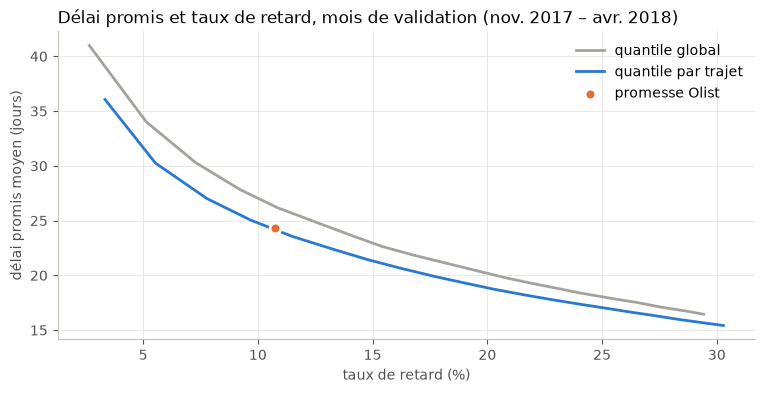

In [8]:
fig, ax = plt.subplots()
for nom, couleur in [("quantile global", GRIS_CLAIR), ("quantile par trajet", BLEU)]:
    ax.plot(courbes[nom]["taux de retard (%)"], courbes[nom]["délai promis moyen (j)"], color=couleur, lw=2, label=nom)
ax.scatter(retard_olist, olist.loc["ensemble", "délai promis moyen (j)"], color=ORANGE, s=60, zorder=3,
           edgecolor="white", linewidth=2, label="promesse Olist")
ax.legend(frameon=False)
ax.set(title="Délai promis et taux de retard, mois de validation (nov. 2017 – avr. 2018)",
       xlabel="taux de retard (%)", ylabel="délai promis moyen (jours)")
plt.show()

Lecture du graphique. Chaque point d'une courbe correspond à un quantile visé. Plus on vise haut,
moins il y a de retard mais plus la promesse est longue. Une courbe plus basse est meilleure car elle
promet moins de jours pour le même taux de retard. Olist n'est qu'un point, puisque sa règle est fixe.

Trois enseignements tirés :
- viser le quantile 0,95 ne garantit pas 5 % de retard. On obtient 11,5 %, parce que les mois
  évalués sont plus lents que le passé appris. Une promesse se juge donc sur le taux de retard
  réellement obtenu, et le quantile visé devra être calibré
- la promesse d'Olist n'est pas naïve. Au même taux de retard, le quantile global promet
  26,3 jours, et la règle par trajet 24,2 jours, contre 24,3 jours pour Olist. Le point orange tombe
  pratiquement sur la courbe bleue
- la barre à battre est donc une courbe qui passe sous la courbe bleue, c'est-à-dire moins de 24,2 jours
  promis pour 10,75 % de retard sur les mois de validation. La comparaison finale avec Olist se fera
  une seule fois, sur les mois de test.

## Ce que le protocole fixe pour la suite

1. **Un réentraînement par mois**, uniquement sur les commandes déjà livrées le 1ᵉʳ du mois.
2. **Validation** sur novembre 2017 à avril 2018, **test** sur mai à juillet 2018, inutilisé
   pour le moment.
3. **Barre de l'estimation** : une MAE de 6,44 jours (médiane par trajet).
4. **Barre de la promesse** : 24,2 jours promis à 10,75 % de retard (règle par trajet), contre
   24,3 jours pour Olist.
5. **Vendeurs inédits** : 5 à 9 % des commandes de chaque mois évalué. Leur erreur sera analysée à
   part.